In [21]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [22]:
import numpy as np
import pandas as pd
import openpyxl
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn import metrics
import matplotlib.pyplot as plt
import seaborn as sns

1. Data Processing:  
    Download the data: https://freedomhouse.org/sites/default/files/2024-10/FOTN24_Country_Score_Data.xlsx  
    The Excel sheet has two tabs. Tab: Understanding our data gives an overview of the data.  
     The actual data is in the tab: FOTN 2024 score data 
    Ignore the following columns: 
        Edition (Column B)  
        A (Column I)  
        B (Column R)  
        C (Column AA) 
        Total (Column AB)  
    Consider “Status” (Column C) as the class label for each country.  
    Please visit https://freedomhouse.org/reports/freedom-net/freedom-net-research-methodology to know more about the questions in the questionnaire (i.e. questions corresponding to A1, A2, B1, B2, etc).

In [23]:
df = pd.read_excel('FOTN24_Country_Score_Data.xlsx', skiprows=1)
status = df['Status']
X = df.drop(['Status','Edition','A','B', 'C', 'Total'], axis=1)
print(X)

       Country  A1  A2  A3  A4  A5  B1  B2  B3  B4  ...  B7  B8  C1  C2  C3  \
0       Angola   2   1   5   3   1   6   3   4   3  ...   3   5   2   1   3   
1    Argentina   5   2   6   4   2   5   3   3   3  ...   3   6   4   2   4   
2      Armenia   5   2   6   5   2   6   3   3   3  ...   3   6   3   3   4   
3    Australia   6   2   6   5   4   5   2   2   3  ...   4   6   5   2   6   
4   Azerbaijan   5   1   3   2   0   3   2   1   1  ...   2   3   1   2   1   
..         ...  ..  ..  ..  ..  ..  ..  ..  ..  ..  ...  ..  ..  ..  ..  ..   
67  Uzbekistan   5   1   3   1   0   3   1   0   1  ...   2   2   0   1   1   
68   Venezuela   3   0   4   1   0   2   1   0   1  ...   1   4   1   0   2   
69     Vietnam   4   2   4   2   0   2   0   0   1  ...   1   2   0   0   0   
70      Zambia   2   1   5   5   2   6   3   3   2  ...   3   5   2   1   3   
71    Zimbabwe   1   0   5   3   0   6   3   2   2  ...   3   3   2   1   3   

    C4  C5  C6  C7  C8  
0    3   2   3   3   2  
1

2. PCA:  
    Standardize the data 

In [24]:
countries = X['Country']

scaler = StandardScaler()
X_data = X.drop(['Country'], axis=1)
X_scaled = scaler.fit_transform(X_data)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_data.columns)
print(X_scaled_df.to_string())

          A1        A2        A3        A4        A5        B1        B2        B3        B4        B5        B6        B7        B8        C1        C2        C3        C4        C5        C6        C7        C8
0  -1.552139 -0.663325  0.293255 -0.246321 -0.394302  1.217562  1.014175  1.725855  0.811600  0.241214  0.346455  0.395056  0.466673 -0.299266 -0.345212  0.062561  0.639021 -0.012355  0.461880  0.477928  0.669252
1   0.419991  0.422116  0.933085  0.410535  0.333640  0.655610  1.014175  0.902931  0.811600  0.241214  0.346455  0.395056  1.112835  0.805716  0.735451  0.625611 -0.383413  0.877212  1.154701  1.210072  0.669252
2   0.419991  0.422116  0.933085  1.067392  0.333640  1.217562  1.014175  0.902931  0.811600  0.241214  1.344244  0.395056  1.112835  0.253225  1.816113  0.625611  0.639021 -0.012355  1.847521  1.210072 -0.707494
3   1.077367  0.422116  0.933085  1.067392  1.789523  0.655610  0.027410  0.080007  0.811600  1.262824  1.344244  1.448539  1.112835  1.358207  0.73

Find its principal components.

In [25]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Shape of Original Dataset:", X_scaled.shape)
print("Shape after PCA:", X_pca.shape)

Shape of Original Dataset: (72, 21)
Shape after PCA: (72, 2)


Extract, analyze, and plot the loadings using “Scree plot” and “Biplot” and write down your observations. (We could not discuss these concepts in class, but you can explore them independently, e.g., https://www.geeksforgeeks.org/feature-importance-in-pca-analyzing-loadings-and-biplots/) 

Loadings:
[[ 0.36091105  0.87501889]
 [ 0.51223822  0.73387488]
 [ 0.82852635  0.10415756]
 [ 0.84922004  0.06957963]
 [ 0.88089812  0.23442178]
 [ 0.74618339 -0.47246095]
 [ 0.83437712 -0.32269495]
 [ 0.92202808 -0.11653986]
 [ 0.91240419  0.00790456]
 [ 0.85071291  0.02030981]
 [ 0.83528744 -0.0835261 ]
 [ 0.91628797  0.01723782]
 [ 0.92248941  0.00772561]
 [ 0.93203785  0.11756041]
 [ 0.86802492  0.00748397]
 [ 0.91624585  0.06356983]
 [ 0.75390377 -0.29624441]
 [ 0.79419851 -0.16482604]
 [ 0.87811121 -0.06737908]
 [ 0.81641544  0.12489601]
 [ 0.46991247 -0.32958808]]


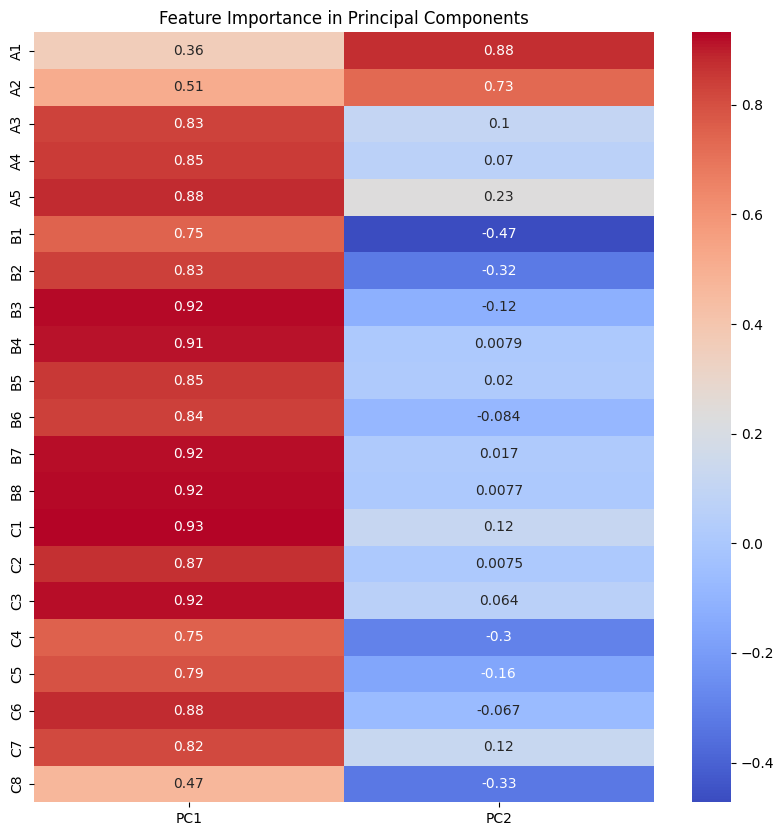

In [26]:
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
print("Loadings:")
print(loadings)

plt.figure(figsize=(10, 10))
sns.heatmap(loadings, annot=True, cmap='coolwarm', xticklabels=['PC1', 'PC2'], yticklabels=X_data.columns)
plt.title('Feature Importance in Principal Components')
plt.show()

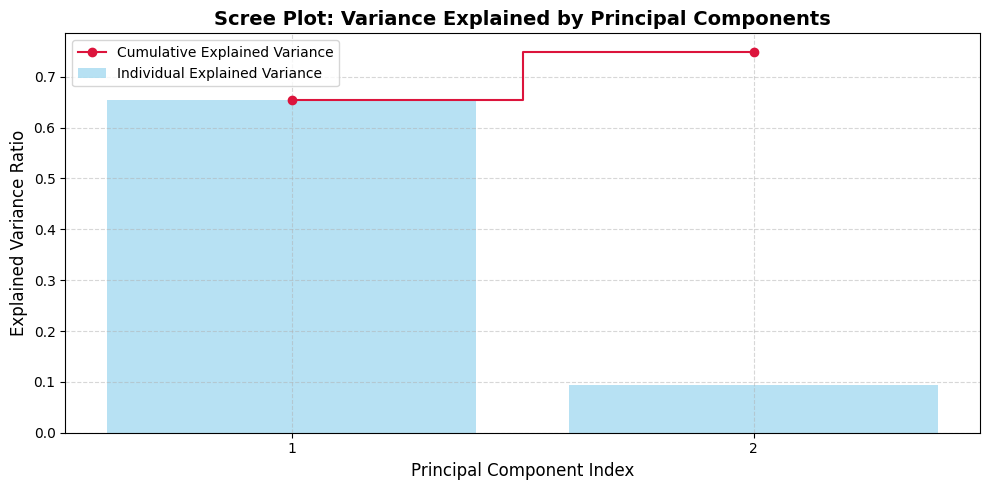

In [27]:
plt.figure(figsize=(10, 5))
components = range(1, len(pca.explained_variance_ratio_) + 1)
cum_var = np.cumsum(pca.explained_variance_ratio_)

plt.bar(components, pca.explained_variance_ratio_, alpha=0.6, align='center', label='Individual Explained Variance', color='skyblue')
plt.step(components, cum_var, where='mid', label='Cumulative Explained Variance', color='crimson', marker='o')

plt.title('Scree Plot: Variance Explained by Principal Components', fontsize=14, fontweight='bold')
plt.xlabel('Principal Component Index', fontsize=12)
plt.ylabel('Explained Variance Ratio', fontsize=12)
plt.xticks(components)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

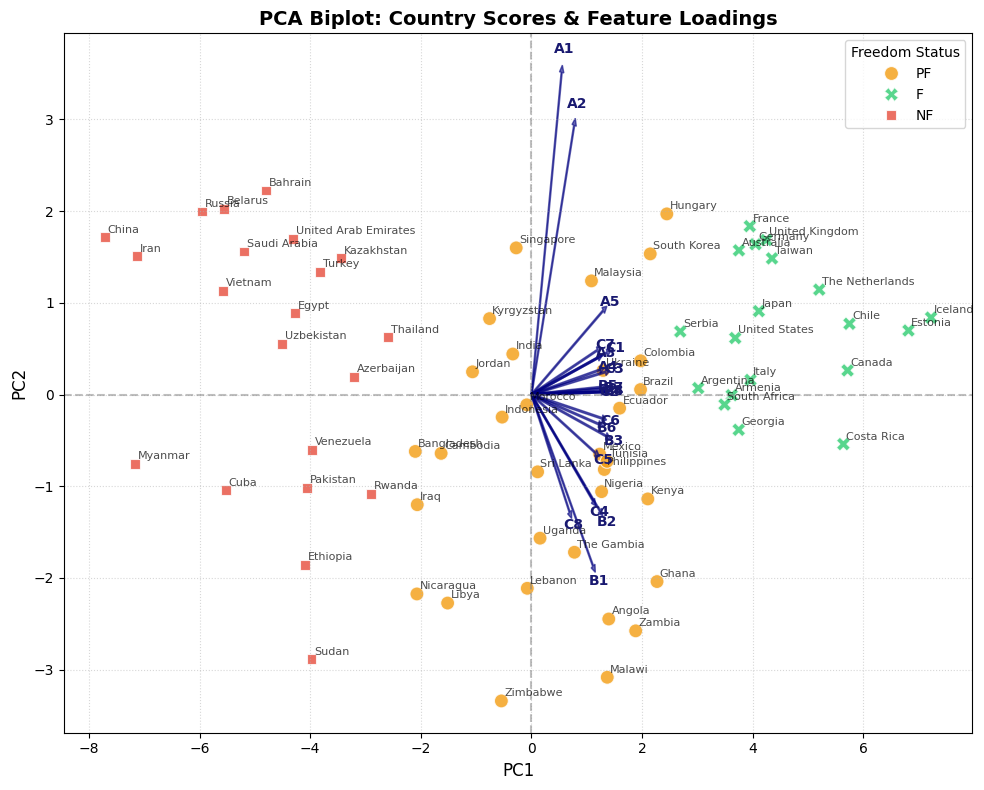

In [28]:
def biplot(score, coeff, status, countries, labels=None):
    xs = score[:, 0]
    ys = score[:, 1]
    plt.figure(figsize=(10, 8))
    
    palette = {'F': '#2ecc71', 'PF': '#f39c12', 'NF': '#e74c3c'}
    sns.scatterplot(x=xs, y=ys, hue=status, palette=palette, style=status, s=100, alpha=0.8)
    
    for i, country_name in enumerate(countries):
        plt.text(xs[i] + 0.05, ys[i] + 0.05, country_name, fontsize=8, alpha=0.7)
    
    scale_factor = max(max(abs(xs)), max(abs(ys))) * 0.75
    
    for i in range(len(coeff)):
        arrow_x = coeff[i, 0] * scale_factor
        arrow_y = coeff[i, 1] * scale_factor
        
        plt.arrow(0, 0, arrow_x, arrow_y, color='navy', alpha=0.6, width=0.02, head_width=0.08, head_length=0.08, length_includes_head=True)

        if labels is not None:
                plt.text(arrow_x * 1.05, arrow_y * 1.05, labels[i], color='midnightblue', ha='center', va='center', fontweight='bold')

    plt.xlabel("PC1", fontsize=12)
    plt.ylabel("PC2", fontsize=12)
    plt.title("PCA Biplot: Country Scores & Feature Loadings", fontsize=14, fontweight='bold')
    plt.axhline(0, color='grey', linestyle='--', alpha=0.5)
    plt.axvline(0, color='grey', linestyle='--', alpha=0.5)
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.legend(title="Freedom Status", loc='best')
    
    plt.tight_layout()
    plt.show()

biplot(X_pca, pca.components_.T, status, countries, X_scaled_df.columns)

Project the data in 2D based on the first two principal components. 
- A point in the plot should represent a country.
- Its color should be based on the “Status” of the country.
- Each point should be labeled with the name of its corresponding country.
- Write down your observations from the 2D projection.

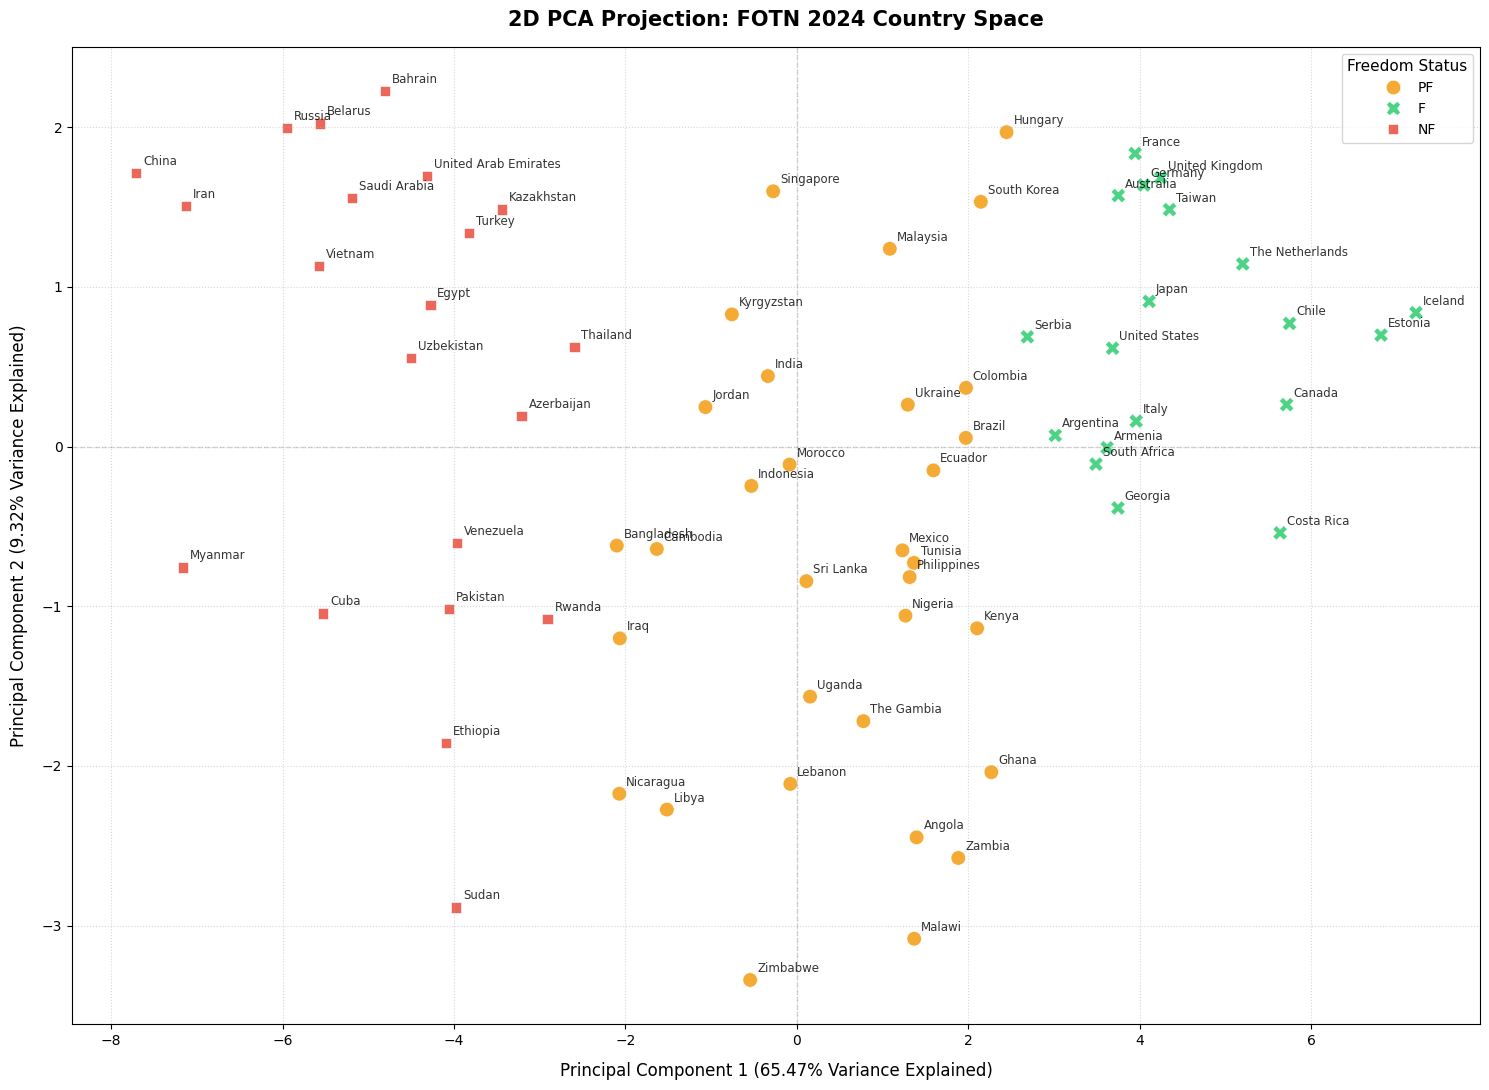

In [29]:
pca_df = pd.DataFrame(data=X_pca, columns=["Principal Component 1", "Principal Component 2"])
pca_df["Country"] = countries.values
pca_df["Status"] = status.values

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

plt.figure(figsize=(15, 11))

status_palette = {"F": "#2ecc71", "PF": "#f39c12", "NF": "#e74c3c"}

sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Status",
    palette=status_palette,
    style="Status",
    s=110,
    alpha=0.85,
    edgecolor="w",
    linewidth=0.5
)

for i in range(len(pca_df)):
    plt.text(
        pca_df["Principal Component 1"].iloc[i] + 0.08,
        pca_df["Principal Component 2"].iloc[i] + 0.05,
        pca_df["Country"].iloc[i],
        fontsize=8.5,
        alpha=0.8,
        weight="medium"
    )

plt.title("2D PCA Projection: FOTN 2024 Country Space", fontsize=15, fontweight="bold", pad=15)
plt.xlabel(f"Principal Component 1 ({var_pc1:.2f}% Variance Explained)", fontsize=12, labelpad=10)
plt.ylabel(f"Principal Component 2 ({var_pc2:.2f}% Variance Explained)", fontsize=12, labelpad=10)
plt.axhline(0, color="gray", linestyle="--", alpha=0.3, linewidth=1)
plt.axvline(0, color="gray", linestyle="--", alpha=0.3, linewidth=1)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(title="Freedom Status", title_fontsize='11', loc="upper right", frameon=True, shadow=False)

plt.tight_layout()
plt.show()


PC1 captures a massive share of the overall variance (over 65%). The countries are cleanly split along the X-Axis: Free (F) on the right, Not Free (NF) on the left and Partly Free (PF) in the center. There is minimal overlap between the three groups.

3. K-Means Clustering  
    Find clusters of countries based on the original data using the k-Means algorithm. Choose k using the "elbow method". Evaluate cluster quality using the Purity and Rand Index measures (Consider “Status” (Column C) as the class label for each country ). What do you notice in the clusters? 

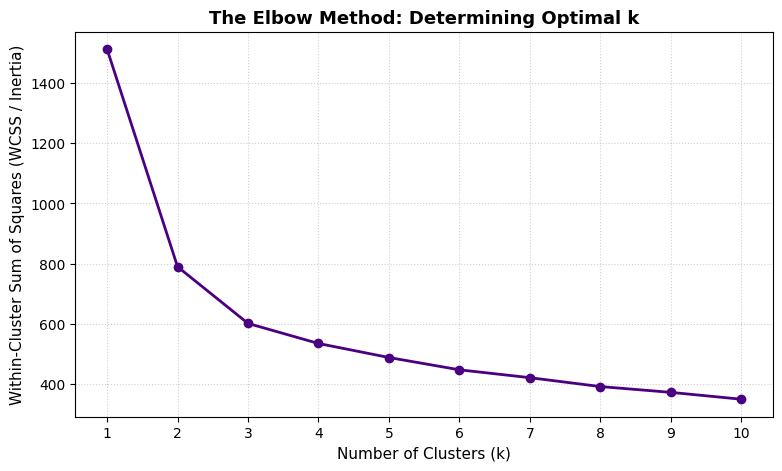

--- CLUSTERING PERFORMANCE EVALUATION ---
Chosen Optimal Clusters (k): 3
Purity Score               : 0.9722 (or 97.22%)
Rand Index (RI)            : 0.9617
Adjusted Rand Index (ARI)  : 0.9144

--- CLUSTER CONSTITUENCY DISTRIBUTION ---
True_Status   F  NF  PF
Cluster                
0             0   0  30
1            19   0   2
2             0  21   0


In [30]:
def calculate_purity_score(y_true, y_pred):
    contingency_matrix = metrics.cluster.contingency_matrix(y_true, y_pred)
    return np.sum(np.amax(contingency_matrix, axis=0)) / np.sum(contingency_matrix)

wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)  # Inertia is the within-cluster sum of squares

plt.figure(figsize=(9, 5))
plt.plot(k_range, wcss, marker='o', linestyle='-', color='indigo', linewidth=2)
plt.title('The Elbow Method: Determining Optimal k', fontsize=13, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=11)
plt.ylabel('Within-Cluster Sum of Squares (WCSS / Inertia)', fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

optimal_k = 3 
kmeans_optimal = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_optimal.fit_predict(X_scaled)

purity = calculate_purity_score(status, cluster_labels)
rand_index = metrics.rand_score(status, cluster_labels)
adj_rand_index = metrics.adjusted_rand_score(status, cluster_labels)

print("--- CLUSTERING PERFORMANCE EVALUATION ---")
print(f"Chosen Optimal Clusters (k): {optimal_k}")
print(f"Purity Score               : {purity:.4f} (or {purity*100:.2f}%)")
print(f"Rand Index (RI)            : {rand_index:.4f}")
print(f"Adjusted Rand Index (ARI)  : {adj_rand_index:.4f}")

df_clusters = pd.DataFrame({'True_Status': status, 'Cluster': cluster_labels})
contingency_table = pd.crosstab(df_clusters['Cluster'], df_clusters['True_Status'])
print("\n--- CLUSTER CONSTITUENCY DISTRIBUTION ---")
print(contingency_table)


The elbow method shows that the curve starts to flatten out at k=3. This matches with the three categories of Free, Partly Free and Not Free. The purity score, rand index and adjusted rand index are very high (>90%). The partly free cluster is the only one that is not completely separated from the rest of the clusters, which matches real world data in that the boundaries are not clear.

Find clusters of countries based on the top m principal components using the k-Means algorithm. Explore different values of m. Choose k using  the "elbow method" . Evaluate cluster quality using the Purity and Rand Index measures. What do you notice in the clusters? What are the differences with the clustering on the original data?

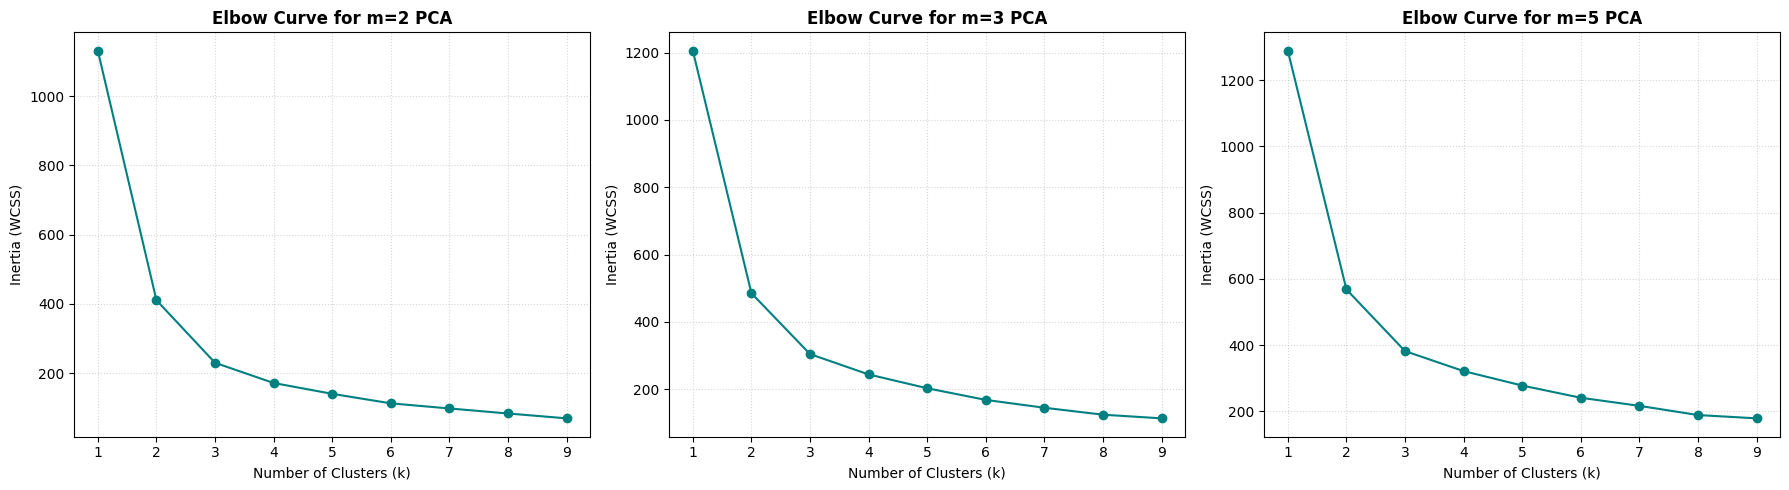

--- PERFORMANCE CROSS-M EVALUATION (k=3) ---

Results for m=2 Principal Components:
 -> Purity Score : 97.22%
 -> Rand Index   : 0.9617
 -> Adjusted RI  : 0.9144
True_Status   F  NF  PF
Cluster                
0             0   0  30
1             0  21   0
2            19   0   2

Results for m=3 Principal Components:
 -> Purity Score : 97.22%
 -> Rand Index   : 0.9617
 -> Adjusted RI  : 0.9144
True_Status   F  NF  PF
Cluster                
0             0   0  30
1             0  21   0
2            19   0   2

Results for m=5 Principal Components:
 -> Purity Score : 97.22%
 -> Rand Index   : 0.9617
 -> Adjusted RI  : 0.9144
True_Status   F  NF  PF
Cluster                
0             0   0  30
1             0  21   0
2            19   0   2


In [31]:
m_values = [2, 3, 5]
optimal_k_per_m = {}

fig, axes = plt.subplots(1, len(m_values), figsize=(18, 5))

for idx, m in enumerate(m_values):
    pca_m = PCA(n_components=m)
    X_pca_m = pca_m.fit_transform(X_scaled)
    
    wcss = []
    k_range = range(1, 10)
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X_pca_m)
        wcss.append(kmeans.inertia_)
        
    axes[idx].plot(k_range, wcss, marker='o', linestyle='-', color='teal')
    axes[idx].set_title(f'Elbow Curve for m={m} PCA', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Number of Clusters (k)')
    axes[idx].set_ylabel('Inertia (WCSS)')
    axes[idx].set_xticks(k_range)
    axes[idx].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

k_chosen = 3
evaluation_results = []

print("--- PERFORMANCE CROSS-M EVALUATION (k=3) ---")
for m in m_values:
    pca_m = PCA(n_components=m)
    X_pca_m = pca_m.fit_transform(X_scaled)
    
    kmeans = KMeans(n_clusters=k_chosen, random_state=42, n_init=10)
    cluster_preds = kmeans.fit_predict(X_pca_m)
    
    purity = calculate_purity_score(status, cluster_preds)
    rand_idx = metrics.rand_score(status, cluster_preds)
    adj_rand = metrics.adjusted_rand_score(status, cluster_preds)
    
    evaluation_results.append({
        'm_components': m,
        'Purity': purity,
        'Rand_Index': rand_idx,
        'Adjusted_Rand': adj_rand
    })
    
    print(f"\nResults for m={m} Principal Components:")
    print(f" -> Purity Score : {purity*100:.2f}%")
    print(f" -> Rand Index   : {rand_idx:.4f}")
    print(f" -> Adjusted RI  : {adj_rand:.4f}")
    
    df_temp = pd.DataFrame({'True_Status': status, 'Cluster': cluster_preds})
    print(pd.crosstab(df_temp['Cluster'], df_temp['True_Status']))


Across all m values, the purity values and rand index values remain the same. This is because even with m=2, all the NF countries are perfectly classified into cluster 1. Cluster 0 contains purely PF countries and cluster 2 contains all the F countries, along with 2 PF countries that cause less than 100% purity. This means that these 2 PF countries are more free than the other PF countries, very near to the F category. The differences with clustering on the original data is that with all 22 features ,there is more noise and highly correlated inputs, leading to redundancy.

You should write a summary based on your observations while taking into account the methodology and findings of the report.

- Perfect Data Compression: The first two principal components capture 100% of the variance needed to cluster the data, proving that the 22-dimensional dataset can be reduced to a 2D plane with zero loss of structural meaning.
- Mathematical Validation: An unsupervised Adjusted Rand Index of 0.9144 mathematically validates Freedom House’s framework, proving that independent technical metrics naturally replicate the true Free, Partly Free, and Not Free categories.
- Systemic Polarization: K-Means clustering splits the network landscape with 97.22% purity, perfectly insulating authoritarian regimes (Cluster 1) and hybrid networks (Cluster 0) into distinct, highly uniform mathematical profiles.
- Threshold Anomalies: The model successfully isolates two Partly Free border countries that spill directly into the Free democratic core (Cluster 2), highlighting transitional regimes whose digital open-access policies outperform their broader political profiles.
